# Análises

In [ ]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src" / "config.py").exists():
    ROOT = Path(r"D:\Projetos\DisciplinaMtL\entrega3")
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg, search, analysis as an
from src.metatask_data import load_meta_task

an.setup_matplotlib()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
cfg.make_dirs()

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(cfg.FIGURES_DIR / f"{name}.{ext}", bbox_inches="tight", facecolor="white")

def save_table(df, name, index=True):
    df.to_csv(cfg.TABLES_DIR / f"{name}.csv", index=index)

from scipy.stats import spearmanr, mannwhitneyu

meta = load_meta_task()
ctx = search.build_context(meta) # vizinhos LODO no PyMFE
names, L, R = ctx["names"], ctx["L"], ctx["R"]
K, n = L.shape[1], L.shape[0]
KEYS = search.all_method_keys()
CURVES = an.load_curves(ctx, KEYS)# se falta rodar algum método, diz qual é
ds_info = an.dataset_table(meta, L, ctx["default_idx"])
WS1, WS3, WS5 = (search.ws_key(k) for k in cfg.K_NEIGHBORS)
print(f"{len(CURVES)} métodos carregados | curvas {next(iter(CURVES.values())).shape} (alvos x sementes x T)")

7 métodos carregados | curvas (120, 5, 100) (alvos x sementes x T)


## Curvas de perda

Os 5 métodos do enunciado, com o warm-start por similaridade em **k = 1** (fixado a priori; k = 3 e 5 na Análise 2). Orçamentos:
**t = 20** (logo após os pontos iniciais), **t = 50** (intermediário) e **t = T = 100**, além da AUC.

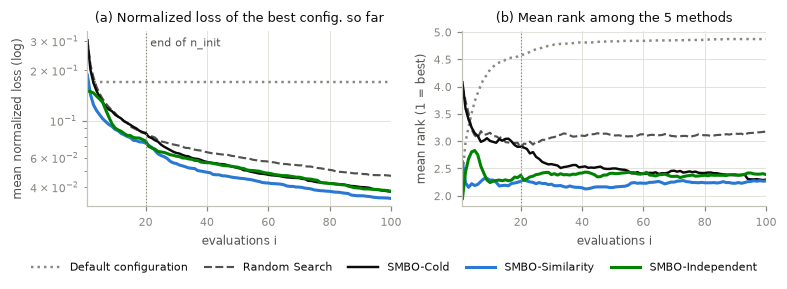

In [2]:
MAIN = ["default", "random_search", "smbo_cold", search.ws_key(cfg.K_MAIN), "smbo_ws_avgrank"]
SHORT = {search.method_label(k): search.method_label(k).replace(f" (k={cfg.K_MAIN})", "") for k in MAIN}
main_curves = {k: CURVES[k] for k in MAIN}

mean_curves = pd.DataFrame({SHORT[search.method_label(k)]: an.per_dataset(c).mean(0) for k, c in main_curves.items()},
                           index=pd.RangeIndex(1, cfg.T_BUDGET + 1, name="i"))
rank_trial = an.average_rank_per_trial(main_curves, names).rename(columns=SHORT)
save_table(mean_curves, "analise1_curvas_media"); save_table(rank_trial, "analise1_rank_por_avaliacao")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
for k in MAIN:
    lab = SHORT[search.method_label(k)]; st = an.style_of(k)
    axes[0].plot(mean_curves.index, mean_curves[lab], label=an.fig_name(lab), **st)
    axes[1].plot(rank_trial.index, rank_trial[lab], label=an.fig_name(lab), **st)
axes[0].set_yscale("log")
axes[0].set(xlabel="evaluations i", ylabel="mean normalized loss (log)", title="(a) Normalized loss of the best config. so far")
axes[1].set(xlabel="evaluations i", ylabel="mean rank (1 = best)", title="(b) Mean rank among the 5 methods")
for ax in axes:
    ax.axvline(cfg.N_INIT, color="#898781", lw=0.8, ls=":")
    ax.set_xlim(1, cfg.T_BUDGET)
axes[0].annotate("end of n_init", (cfg.N_INIT, 1), xycoords=("data", "axes fraction"), xytext=(3, -10),
                 textcoords="offset points", fontsize=7, color="#52514e")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.0), fontsize=7.5,
           handlelength=2.6, columnspacing=1.4)
save_fig(fig, "analise1_curvas"); plt.show()

In [3]:
summary1 = an.summary_table(main_curves, names).rename(index=SHORT).sort_values("AUC")
save_table(summary1, "analise1_resumo")
print("Perda normalizada média (alvos x sementes) em t = n_init, intermediário e T; AUC = média da curva em i = 1..T:")
display(summary1.style.format("{:.4f}", subset=[c for c in summary1.columns if c != "rank médio (AUC)"])
        .format("{:.2f}", subset=["rank médio (AUC)"]).highlight_min(color="#cde2fb"))

Perda normalizada média (alvos x sementes) em t = n_init, intermediário e T; AUC = média da curva em i = 1..T:


,t=20,t=50,t=100,AUC,rank médio (AUC)
SMBO-Similarity,0.0733,0.0453,0.0341,0.0549,2.11
SMBO-Independent,0.0755,0.0526,0.0377,0.0604,2.17
SMBO-Cold,0.0842,0.0520,0.0375,0.0652,2.79
Random Search,0.0834,0.0606,0.0467,0.0722,3.27
Configuração padrão,0.1700,0.1700,0.1700,0.1700,4.65


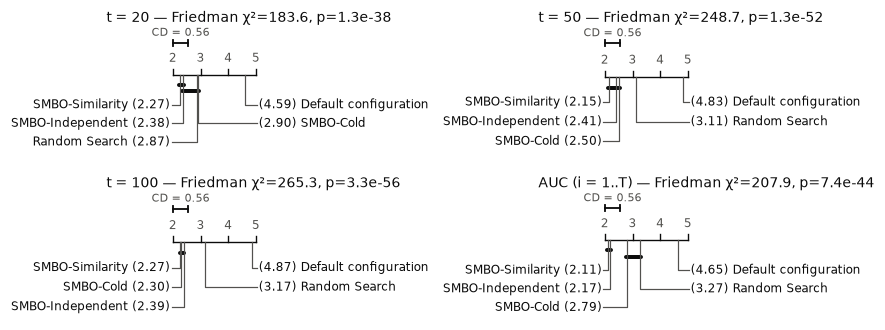

orçamento,t = 20,t = 50,t = 100,AUC (i = 1..T)
Friedman χ²,183.5617,248.6556,265.3221,207.9197
p,0.0000,0.0000,0.0000,0.0000
CD (Nemenyi),0.5568,0.5568,0.5568,0.5568
rank SMBO-Similarity,2.2667,2.1500,2.2708,2.1083
rank SMBO-Independent,2.3750,2.4125,2.3875,2.1750
rank Random Search,2.8708,3.1083,3.1750,3.2750
rank SMBO-Cold,2.9000,2.5000,2.2958,2.7917
rank Configuração padrão,4.5875,4.8292,4.8708,4.6500


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(7.6, 3.4), gridspec_kw={"wspace": 1.0, "hspace": 0.35})
tests1 = []
for ax, at in zip(axes.ravel(), [cfg.N_INIT, 50, cfg.T_BUDGET, "AUC"]):
    data = an.values_at(main_curves, names, at).rename(columns=SHORT)
    res = an.friedman_nemenyi(data)
    tag = f"t = {at}" if at != "AUC" else "AUC (i = 1..T)"
    an.plot_cd(res, ax, title=f"{tag} — Friedman χ²={res['friedman_stat']:.1f}, p={res['friedman_p']:.1e}")
    tests1.append({"orçamento": tag, "Friedman χ²": res["friedman_stat"], "p": res["friedman_p"], "CD (Nemenyi)": res["cd"],
                   **{f"rank {m}": v for m, v in res["ranks"].items()}})
save_fig(fig, "analise1_cd"); plt.show()          # sem tight_layout: o espaçamento entre colunas acomoda os nomes
tests1 = pd.DataFrame(tests1).set_index("orçamento"); save_table(tests1, "analise1_friedman_nemenyi")
display(tests1.T.round(4))

In [5]:
# Wilcoxon pareado (Holm dentro de cada orçamento) entre os três SMBO
PAIRS = [("SMBO-Similarity", "SMBO-Cold"), ("SMBO-Independent", "SMBO-Cold"), ("SMBO-Similarity", "SMBO-Independent")]
rows = []
for at in [cfg.N_INIT, 50, cfg.T_BUDGET, "AUC"]:
    data = an.values_at(main_curves, names, at).rename(columns=SHORT)
    pt = an.paired_tests(data, PAIRS); pt.insert(0, "orçamento", at); rows.append(pt)
pairs1 = pd.concat(rows, ignore_index=True); save_table(pairs1, "analise1_wilcoxon", index=False)
display(pairs1.round(4))

,orçamento,A,B,média A,média B,B − A,A melhor,empates,A pior,p (Wilcoxon),p (Holm),signif.
0,20,SMBO-Similarity,SMBO-Cold,0.0733,0.0842,0.0109,74,11,35,0.0030,0.0089,True
1,20,SMBO-Independent,SMBO-Cold,0.0755,0.0842,0.0087,66,15,39,0.0065,0.0130,True
2,20,SMBO-Similarity,SMBO-Independent,0.0733,0.0755,0.0022,51,27,42,0.4608,0.4608,False
3,50,SMBO-Similarity,SMBO-Cold,0.0453,0.0520,0.0067,67,16,37,0.0169,0.0506,False
4,50,SMBO-Independent,SMBO-Cold,0.0526,0.0520,-0.0006,53,16,51,0.8994,0.8994,False
5,50,SMBO-Similarity,SMBO-Independent,0.0453,0.0526,0.0073,56,22,42,0.1344,0.2687,False
6,100,SMBO-Similarity,SMBO-Cold,0.0341,0.0375,0.0034,49,21,50,0.4636,0.9272,False
7,100,SMBO-Independent,SMBO-Cold,0.0377,0.0375,-0.0001,50,22,48,0.9675,0.9675,False
8,100,SMBO-Similarity,SMBO-Independent,0.0341,0.0377,0.0035,51,28,41,0.2127,0.6382,False
9,AUC,SMBO-Similarity,SMBO-Cold,0.0549,0.0652,0.0104,82,0,38,0.0002,0.0005,True


## O papel das meta-características

Pra ver se a similaridade de fato escolhe bons vizinhos, isolei a fase inicial (sem SMBO) e comparei o vizinho escolhido com o melhor vizinho possível (oráculo) e com um vizinho qualquer (média sobre os 119).

In [6]:
ws_keys = [search.ws_key(k) for k in cfg.K_NEIGHBORS]
curves2 = {k: CURVES[k] for k in ws_keys + ["smbo_ws_avgrank", "smbo_cold"]}
rows2 = []
for at in [cfg.N_INIT, 50, cfg.T_BUDGET, "AUC"]:
    data = an.values_at(curves2, names, at)
    pairs = [(search.method_label(k), ref) for ref in ["SMBO-Independent", "SMBO-Cold"] for k in ws_keys]
    pt = an.paired_tests(data, pairs)          # Holm sobre as 6 comparações do orçamento (3 valores de k x 2 referências)
    pt.insert(0, "orçamento", at); rows2.append(pt)
tab2 = pd.concat(rows2, ignore_index=True); save_table(tab2, "analise2_ws_vs_referencias", index=False)
summary2 = an.summary_table(curves2, names)
save_table(summary2, "analise2_resumo")
display(summary2.round(4))
display(tab2[["orçamento", "A", "B", "média A", "média B", "A melhor", "empates", "A pior", "p (Holm)", "signif."]].round(4))

,t=20,t=50,t=100,AUC,rank médio (AUC)
SMBO-Similarity (k=1),0.0733,0.0453,0.0341,0.0549,2.7375
SMBO-Similarity (k=3),0.0635,0.0452,0.0338,0.0531,2.7125
SMBO-Similarity (k=5),0.0645,0.0438,0.0326,0.0525,2.6917
SMBO-Independent,0.0755,0.0526,0.0377,0.0604,3.0167
SMBO-Cold,0.0842,0.0520,0.0375,0.0652,3.8417


,orçamento,A,B,média A,média B,A melhor,empates,A pior,p (Holm),signif.
0,20,SMBO-Similarity (k=1),SMBO-Independent,0.0733,0.0755,51,27,42,0.4608,False
1,20,SMBO-Similarity (k=3),SMBO-Independent,0.0635,0.0755,56,27,37,0.0856,False
2,20,SMBO-Similarity (k=5),SMBO-Independent,0.0645,0.0755,59,21,40,0.1364,False
3,20,SMBO-Similarity (k=1),SMBO-Cold,0.0733,0.0842,74,11,35,0.0119,True
4,20,SMBO-Similarity (k=3),SMBO-Cold,0.0635,0.0842,82,13,25,0.0000,True
5,20,SMBO-Similarity (k=5),SMBO-Cold,0.0645,0.0842,79,16,25,0.0000,True
6,50,SMBO-Similarity (k=1),SMBO-Independent,0.0453,0.0526,56,22,42,0.1714,False
7,50,SMBO-Similarity (k=3),SMBO-Independent,0.0452,0.0526,56,21,43,0.1714,False
8,50,SMBO-Similarity (k=5),SMBO-Independent,0.0438,0.0526,54,19,47,0.1714,False
9,50,SMBO-Similarity (k=1),SMBO-Cold,0.0453,0.0520,67,16,37,0.0674,False


In [ ]:
# Fase inicial isolada (sem SMBO): perda após os n_init pontos em função de k = 1..20
# oráculo e vizinho aleatório (k = 1)
orders = an.config_orders(L, cfg.N_SEEDS)
init_k = an.init_regret_vs_k(ctx, orders).mean()
init_k.index.name = "k"; save_table(init_k.rename("perda após n_init").to_frame(), "analise2_fase_inicial_por_k")
M = an.transfer_matrix(ctx, orders)            # M[i, j]: perda em i com as 20 melhores configurações de j
indep_init = an.per_dataset(CURVES["smbo_ws_avgrank"])[:, cfg.N_INIT - 1].mean()
cold_init = an.per_dataset(CURVES["smbo_cold"])[:, cfg.N_INIT - 1].mean()
quality = an.neighbor_quality(ctx, M)
quality.loc["SMBO-Independent", "perda após n_init (vizinho escolhido)"] = indep_init
quality.loc["SMBO-Cold (20 aleatórias)", "perda após n_init (vizinho escolhido)"] = cold_init
save_table(quality, "analise2_qualidade_vizinho")
display(init_k.loc[[1, 2, 3, 5, 8, 10, 20]].round(4).to_frame("perda após n_init").T)
display(quality.round(4))

k,1,2,3,5,8,10,20
perda após n_init,0.0698,0.062,0.0649,0.0644,0.0615,0.0646,0.0665


,perda após n_init (vizinho escolhido),percentil do vizinho (0 = melhor),"ρ(distância, perda transferida) médio",p (Wilcoxon ρ ≠ 0)
PyMFE,0.0698,42.1045,0.0104,0.5466
Oráculo (melhor vizinho),0.0078,0.0000,NaN,NaN
Vizinho aleatório,0.0779,50.0000,NaN,NaN
SMBO-Independent,0.0755,NaN,NaN,NaN
SMBO-Cold (20 aleatórias),0.0842,NaN,NaN,NaN


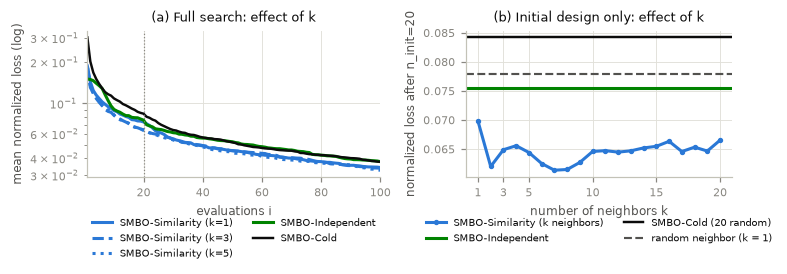

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for key in ws_keys + ["smbo_ws_avgrank", "smbo_cold"]:
    ax.plot(range(1, cfg.T_BUDGET + 1), an.per_dataset(CURVES[key]).mean(0), label=an.fig_name(search.method_label(key)),
            **an.style_of(key))
ax.set_yscale("log"); ax.set_xlim(1, cfg.T_BUDGET)
ax.axvline(cfg.N_INIT, color="#898781", lw=0.8, ls=":")
ax.set(xlabel="evaluations i", ylabel="mean normalized loss (log)", title="(a) Full search: effect of k")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=6.5)

ax = axes[1]
ax.plot(init_k.index, init_k.values, color=an.WS_COLOR, lw=2, marker="o", ms=2.5, label="SMBO-Similarity (k neighbors)")
ax.axhline(indep_init, label="SMBO-Independent", **an.FIXED_STYLE["smbo_ws_avgrank"])
ax.axhline(cold_init, label="SMBO-Cold (20 random)", **an.FIXED_STYLE["smbo_cold"])
ax.axhline(np.nanmean(M, axis=1).mean(), label="random neighbor (k = 1)", **an.FIXED_STYLE["random_search"])
ax.set(xlabel="number of neighbors k", ylabel=f"normalized loss after n_init={cfg.N_INIT}",
       title="(b) Initial design only: effect of k", xticks=[1, 3, 5, 10, 15, 20])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=6.5)
fig.tight_layout(); save_fig(fig, "analise2_k"); plt.show()

## Quando o warm-start falha

Para explicar as falhas usei a similaridade "verdadeira" entre alvo e vizinho que foi o ρ de Spearman entre as perdas das 3456 configurações nos dois datasets.

In [9]:
S_land = an.landscape_similarity(L)                  # ρ de Spearman entre as perdas das K configs de cada par de datasets
key = search.ws_key(cfg.K_MAIN)
gain = an.auc(CURVES["smbo_cold"]) - an.auc(CURVES[key])
nb_, dist = ctx["neighbors"], ctx["distances"]
nn = nb_[:, 0]
rel = dist[:, 0] / np.median(dist, axis=1)
land = S_land[np.arange(n), nn]
fail = pd.DataFrame({
    "ganho AUC": gain, "dist. relativa NN": rel, "dist. absoluta NN": dist[:, 0], "vizinho": [names[j] for j in nn],
    "ρ paisagem alvo~vizinho": land, "melhor ρ paisagem possível": np.nanmax(S_land, axis=1),
    "perda após n_init (SMBO-Similarity)": an.per_dataset(CURVES[key])[:, cfg.N_INIT - 1],
    "perda após n_init (SMBO-Cold)": an.per_dataset(CURVES["smbo_cold"])[:, cfg.N_INIT - 1],
    "frac. configs no ótimo": ds_info["frac. configs no ótimo"].to_numpy(),
    "n_instancias": ds_info["n_instancias"].to_numpy(), "n_classes": ds_info["n_classes"].to_numpy()}, index=names)
save_table(fail.sort_values("ganho AUC"), "analise3_por_alvo")

worse, better = fail[fail["ganho AUC"] < -1e-9], fail[fail["ganho AUC"] > 1e-9]
corr = {"distância relativa": spearmanr(rel, gain), "distância absoluta": spearmanr(dist[:, 0], gain),
        "ρ paisagem alvo~vizinho": spearmanr(land, gain),
        "perda após n_init (SMBO-Similarity)": spearmanr(fail["perda após n_init (SMBO-Similarity)"], gain)}
corr_tab = pd.DataFrame({k: {"ρ Spearman com o ganho": v.statistic, "p": v.pvalue} for k, v in corr.items()}).T
save_table(corr_tab, "analise3_correlacoes")
print(f"SMBO-Similarity melhor que o SMBO-Cold em {len(better)} alvos, pior em {len(worse)}, empate em {n - len(better) - len(worse)}")
display(corr_tab.round(4))

cmp = pd.DataFrame({col: {"mediana (Similarity pior)": worse[col].median(), "mediana (Similarity melhor)": better[col].median(),
                          "p (Mann-Whitney)": mannwhitneyu(worse[col], better[col]).pvalue}
                    for col in ["ρ paisagem alvo~vizinho", "dist. relativa NN", "perda após n_init (SMBO-Similarity)",
                                "frac. configs no ótimo", "n_instancias", "n_classes"]}).T
save_table(cmp, "analise3_pior_vs_melhor")
display(cmp.round(4))

SMBO-Similarity melhor que o SMBO-Cold em 82 alvos, pior em 38, empate em 0


,ρ Spearman com o ganho,p
distância relativa,-0.0869,0.3453
distância absoluta,-0.1252,0.1729
ρ paisagem alvo~vizinho,0.3763,0.0000
perda após n_init (SMBO-Similarity),-0.2726,0.0026


,mediana (Similarity pior),mediana (Similarity melhor),p (Mann-Whitney)
ρ paisagem alvo~vizinho,0.2660,0.6416,0.0000
dist. relativa NN,0.5503,0.5180,0.1731
perda após n_init (SMBO-Similarity),0.1106,0.0243,0.0000
frac. configs no ótimo,0.0007,0.0006,0.4923
n_instancias,569.5000,768.0000,0.3019
n_classes,2.0000,3.0000,0.0287


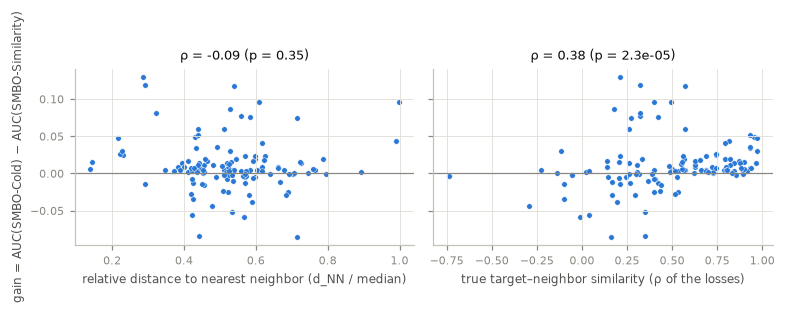

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), sharey=True)
for ax, x, lab, c in [(axes[0], rel, "relative distance to nearest neighbor (d_NN / median)", corr["distância relativa"]),
                      (axes[1], land, "true target–neighbor similarity (ρ of the losses)", corr["ρ paisagem alvo~vizinho"])]:
    ax.axhline(0, color="#898781", lw=0.8)
    ax.scatter(x, gain, s=13, color=an.WS_COLOR, edgecolor="white", linewidth=0.3)
    ax.set(xlabel=lab, title=f"ρ = {c.statistic:.2f} (p = {c.pvalue:.2g})")
axes[0].set_ylabel("gain = AUC(SMBO-Cold) − AUC(SMBO-Similarity)")
fig.tight_layout(); save_fig(fig, "analise3_ganho"); plt.show()

In [11]:
print("Os 12 alvos em que o warm-start mais perdeu para o SMBO-Cold:")
display(fail.sort_values("ganho AUC").head(12).round(4))

Os 12 alvos em que o warm-start mais perdeu para o SMBO-Cold:


,ganho AUC,dist. relativa NN,dist. absoluta NN,vizinho,ρ paisagem alvo~vizinho,melhor ρ paisagem possível,perda após n_init (SMBO-Similarity),perda após n_init (SMBO-Cold),frac. configs no ótimo,n_instancias,n_classes
lung-cancer,-0.0855,0.7140,2.9529,molec-biol-promoter,0.1624,0.3830,0.2500,0.0000,0.0897,32,3
cylinder-bands,-0.0837,0.4417,1.0026,heart-hungarian,0.3517,0.8036,0.3333,0.1667,0.0009,512,2
post-operative,-0.0592,0.5674,1.4713,breast-cancer,-0.0118,0.4825,0.1000,0.0600,0.0049,90,3
echocardiogram,-0.0555,0.4220,0.9525,heart-hungarian,0.0364,0.3809,0.2308,0.0769,0.0023,131,2
contrac,-0.0515,0.5335,1.4011,heart-cleveland,0.3490,0.8018,0.1550,0.0929,0.0003,1473,3
parkinsons,-0.0432,0.4778,1.2278,breast-cancer-wisc-prog,-0.2941,0.7884,0.0952,0.0381,0.0026,195,2
lymphography,-0.0381,0.5886,1.3420,heart-cleveland,0.1936,0.7075,0.1875,0.1125,0.0006,148,4
ilpd-indian-liver,-0.0345,0.4239,0.9518,pima,-0.0970,0.3178,0.2121,0.1394,0.0003,583,2
balloons,-0.0295,0.5798,1.6383,tic-tac-toe,0.1650,0.2315,0.1500,0.1500,0.0362,16,2
lenses,-0.0290,0.6827,2.2464,pittsburg-bridges-MATERIAL,0.2916,0.3542,0.1500,0.0000,0.0871,24,3


## O preço de restringir a busca às K configurações

Com a matriz completa a busca é simulada e L\* é exato — mas só **dentro do grid**. Alguns indícios do que isso esconde:

In [12]:
found = pd.DataFrame({SHORT[search.method_label(k)]: {
    "alvos com o ótimo do grid achado até T (%)": 100 * (an.per_dataset(CURVES[k])[:, -1] <= 1e-12).mean(),
    "avaliações até o ótimo (mediana, quando acha)": np.nanmedian(np.where(
        (CURVES[k] <= 1e-12).any(-1), (CURVES[k] > 1e-12).sum(-1) + 1, np.nan))} for k in MAIN}).T
save_table(found, "restricao_K_otimo_achado"); display(found.round(1))
print(f"Resolução da perda: mediana de {int(ds_info['valores distintos de perda'].median())} valores distintos entre as "
      f"{K} configurações; em {int((ds_info['frac. configs no ótimo'] >= 0.01).sum())} datasets >= 1% das configurações "
      f"empatam no ótimo.")
Yt = meta.Y_test.astype(float)
test_gap = Yt.max(1) - Yt[np.arange(n), L.argmin(1)]
rho_vt = np.array([spearmanr(L[i], 1 - Yt[i]).statistic for i in range(n)])
print(f"Validação x teste: escolher o ótimo de VALIDAÇÃO custa, em acurácia de teste, mediana {np.median(test_gap):.3f} "
      f"(média {test_gap.mean():.3f}) em relação ao ótimo de teste; ρ de Spearman médio entre as perdas de validação e de teste "
      f"das K configurações = {np.nanmean(rho_vt):.2f}.")

,alvos com o ótimo do grid achado até T (%),"avaliações até o ótimo (mediana, quando acha)"
Configuração padrão,5.8,1.0
Random Search,12.5,15.0
SMBO-Cold,10.8,26.0
SMBO-Similarity,19.2,23.0
SMBO-Independent,18.3,16.0


Resolução da perda: mediana de 44 valores distintos entre as 3456 configurações; em 18 datasets >= 1% das configurações empatam no ótimo.
Validação x teste: escolher o ótimo de VALIDAÇÃO custa, em acurácia de teste, mediana 0.043 (média 0.085) em relação ao ótimo de teste; ρ de Spearman médio entre as perdas de validação e de teste das K configurações = 0.72.


In [13]:
for sub in ["tables", "figures"]:
    files = sorted((cfg.RESULTS_DIR / sub).glob("*"))
    print(f"results/{sub}/ ({len(files)}):", ", ".join(f.name for f in files))

results/tables/ (16): analise1_curvas_media.csv, analise1_friedman_nemenyi.csv, analise1_rank_por_avaliacao.csv, analise1_resumo.csv, analise1_wilcoxon.csv, analise2_fase_inicial_por_k.csv, analise2_qualidade_vizinho.csv, analise2_resumo.csv, analise2_ws_vs_referencias.csv, analise3_correlacoes.csv, analise3_pior_vs_melhor.csv, analise3_por_alvo.csv, buscas_conferencia.csv, datasets_resumo.csv, restricao_K_otimo_achado.csv, vizinhos_pymfe.csv
results/figures/ (10): analise1_cd.pdf, analise1_cd.png, analise1_curvas.pdf, analise1_curvas.png, analise2_k.pdf, analise2_k.png, analise3_ganho.pdf, analise3_ganho.png, etapa1_meta_dados.pdf, etapa1_meta_dados.png
